# Domestic Flight Price Prediction — complete pipeline

From the raw CSVs to the submission file, with every decision backed by an experiment.

| Section | What it does |
|---|---|
| 1 | Load data, data dictionary |
| 2 | EDA: target skew, feature imbalance, price drivers, duplicate rows |
| 3 | Missing values: airline recovered exactly; duration imputation (9 methods compared) |
| 4 | Feature engineering, information gain (mutual information), encoding comparison incl. rare-level grouping |
| 5 | Target transform (raw vs log) |
| 5b | **Feature selection:** redundancy, ablation study, permutation importance, blend on selected features |
| 6 | Model comparison (5-fold CV): simple/multiple linear, polynomial, Ridge, Lasso, KNN, decision tree, random forest, extra trees, gradient boosting, LightGBM, XGBoost ×2, CatBoost |
| 7 | Blend-weight search on out-of-fold predictions |
| 8 | Final 3-model blend fitted on all of train |
| 9 | Exact-twin override |
| 10 | Generalisation checks (fold stability, weight sensitivity, simulated hidden 40%, adversarial validation) |
| 11 | Experiment and leaderboard log |

**Final model:** a blend of 3 models trained on `log1p(price)`: **55% XGBoost (native categorical) + 30% Random Forest + 15% Extra Trees**, followed by the exact-twin rule.

With `FEATURE_SET = 'all14'` the notebook reproduces submission **H** (public LB **0.96317**). `'raw9'` gives candidate **J**, which section 5b's feature-selection result motivates.

**Switches (first code cell)**
- `RUN_COMPARISONS = False` skips the comparison/evidence sections. The submission is identical; ~2 min instead of ~15–20 min on 2 CPUs.
- `RUN_CATBOOST = False` skips the slowest comparison model.

In [1]:
import os, glob, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.model_selection import KFold
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.decomposition import TruncatedSVD
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import lightgbm as lgb
import xgboost as xgb
warnings.filterwarnings('ignore')

RNG = 42
FEATURE_SET = 'all14'      # 'all14' -> submission H (LB 0.96317) | 'raw9' -> candidate J (see section 5b)
RUN_COMPARISONS = True    # False = skip the comparison/evidence sections (same submission, much faster)
RUN_CATBOOST = True       # only used when RUN_COMPARISONS is True
np.random.seed(RNG)

# Find the data: Kaggle input folder, or the current folder
cands = sorted(glob.glob('/kaggle/input/*/train.csv')) + ['./train.csv']
DATA_DIR = os.path.dirname(next(p for p in cands if os.path.exists(p)))
print('data from:', os.path.abspath(DATA_DIR))

data from: /tmp/claude-0/-home-claude/f9badd5a-d164-5978-8e86-fefd734c82e7/scratchpad/flight/nbrun_full


In [2]:
# Chart style: light surface, recessive grid, one blue for single-series charts
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e6e5e1', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titlesize': 12, 'axes.titleweight': 'semibold',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10, 'figure.dpi': 110,
})

## 1. Load data

In [3]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
sample = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
print('train', train.shape, '| test', test.shape, '| sample', sample.shape)
train.head()

train (15589, 12) | test (3898, 11) | sample (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


In [4]:
info = pd.DataFrame({'dtype': train.dtypes.astype(str),
                     'n_unique': train.nunique(),
                     'null_train_%': (train.isna().mean()*100).round(1),
                     'null_test_%': (test.reindex(columns=train.columns).isna().mean()*100).round(1)})
info

,dtype,n_unique,null_train_%,null_test_%
id,int64,15589,0.0,0.0
airline,str,18,19.8,20.5
flight,str,1070,0.0,0.0
source_city,str,6,0.0,0.0
departure_time,str,6,0.0,0.0
stops,str,3,0.0,0.0
arrival_time,str,6,0.0,0.0
destination_city,str,6,0.0,0.0
flight_class,str,2,0.0,0.0
duration,float64,243,19.9,19.9


**Data dictionary**

| Column | Meaning |
|---|---|
| `id` | row identifier |
| `airline` | carrier (≈20% missing) |
| `flight` | flight number, e.g. `IX 1070`; the prefix is the carrier code |
| `source_city`, `destination_city` | origin and destination (6 cities) |
| `departure_time`, `arrival_time` | time-of-day slot (6 levels) |
| `stops` | `zero`, `one`, `two_or_more` |
| `flight_class` | `Economy` or `Business` |
| `duration` | flight time in hours (≈20% missing) |
| `days_left` | days between booking and departure (1–57) |
| `price` | **target**, ticket price in ₹ (train only) |

In [5]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,15589.0,7795.000000,4500.301008,1.00,3898.00,7795.0,11692.00,15589.00
duration,12494.0,4.300499,4.181832,0.92,2.25,2.5,4.92,38.08
days_left,15589.0,22.461928,13.036812,1.00,12.00,22.0,33.00,57.00
price,15589.0,29816.695555,39127.890925,3801.00,7210.00,10183.0,35968.00,323177.00


## 2. EDA
### 2.1 Target: `price` is strongly right-skewed

price skew = 2.70 | log1p(price) skew = 0.71
median ₹10,183  vs  mean ₹29,817  (max ₹323,177)


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


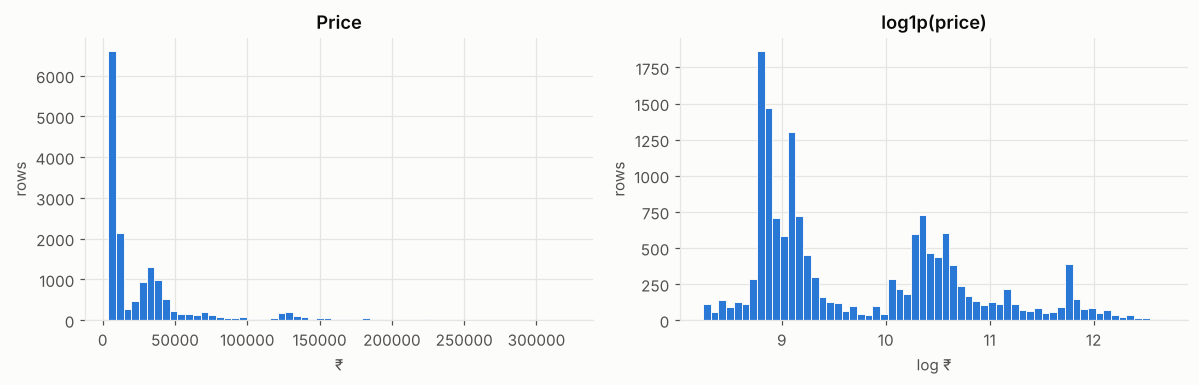

In [6]:
print(f"price skew = {skew(train.price):.2f} | log1p(price) skew = {skew(np.log1p(train.price)):.2f}")
print(f"median ₹{train.price.median():,.0f}  vs  mean ₹{train.price.mean():,.0f}  (max ₹{train.price.max():,.0f})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(train.price, bins=60, color=BLUE, edgecolor=SURF, linewidth=0.6)
ax[0].set(title='Price', xlabel='₹', ylabel='rows')
ax[1].hist(np.log1p(train.price), bins=60, color=BLUE, edgecolor=SURF, linewidth=0.6)
ax[1].set(title='log1p(price)', xlabel='log ₹', ylabel='rows')
plt.tight_layout(); plt.show()

The distribution is bimodal: Economy fares cluster low and Business fares high. The log transform tames the long tail, so all models are trained on `log1p(price)`; section 5 compares this choice.

### 2.2 Categorical features and imbalance

In [7]:
cat_raw = ['airline','source_city','departure_time','stops','arrival_time','destination_city','flight_class']
for c in cat_raw:
    vc = train[c].value_counts(dropna=False)
    print(f"{c:17s} {train[c].nunique():2d} levels | largest {vc.index[0]} {vc.iloc[0]/len(train)*100:.0f}% | smallest {vc.index[-1]} {vc.iloc[-1]} rows")

airline           18 levels | largest Wayfarer Aviation 33% | smallest Cyberdyne Flights 2 rows
source_city        6 levels | largest Metropolis 40% | smallest Los Santos 1503 rows
departure_time     6 levels | largest Evening 21% | smallest Late_Night 1015 rows
stops              3 levels | largest zero 70% | smallest two_or_more 66 rows
arrival_time       6 levels | largest Night 25% | smallest Early_Morning 974 rows
destination_city   6 levels | largest Night City 30% | smallest Gotham 1562 rows
flight_class       2 levels | largest Economy 59% | smallest Business 6380 rows


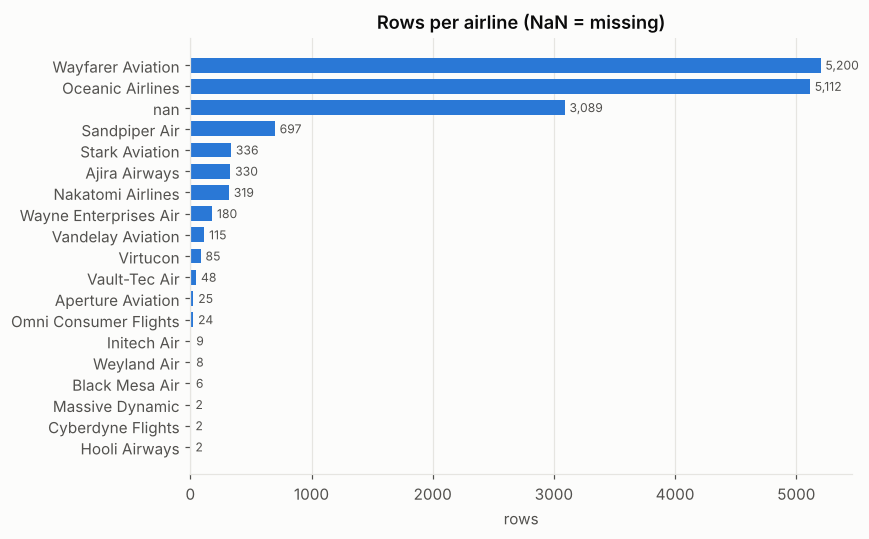

In [8]:
vc = train.airline.value_counts(dropna=False).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([str(i) for i in vc.index], vc.values, color=BLUE, height=0.7)
for i, v in enumerate(vc.values): ax.text(v + 40, i, f'{v:,}', va='center', color=INK2, fontsize=8)
ax.set(title='Rows per airline (NaN = missing)', xlabel='rows'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

`price` is continuous, so there is no *class* imbalance in the target. The imbalance is in the features:
- Two airlines make up ~80% of rows, and several have fewer than 10.
- `stops = two_or_more` is 0.4% of rows.

Section 4 tests whether grouping rare airlines helps. The target's skew is handled with the log transform.

### 2.3 What drives price

In [9]:
cols = ['flight_class','stops','departure_time','source_city']
summary = {c: train.groupby(c).price.agg(['count','median','mean']).round(0).sort_values('median') for c in cols}
for c in cols: print(f'--- {c}'); print(summary[c].to_string(), '\n')

--- flight_class
              count   median     mean
flight_class                         
Economy        9209   7587.0   8818.0
Business       6380  38546.0  60127.0 

--- stops
             count    median      mean
stops                                 
zero         10965    8883.0   15508.0
one           4558   40528.0   62782.0
two_or_more     66  125611.0  130463.0 

--- departure_time
                count   median     mean
departure_time                         
Evening          3304   9450.0  20973.0
Afternoon        2462   9802.0  22147.0
Early_Morning    2680   9943.0  30279.0
Morning          3296  10864.0  33654.0
Night            2832  11000.0  33498.0
Late_Night       1015  33067.0  53257.0 

--- source_city
             count   median     mean
source_city                         
Metropolis    6198   8976.0  17740.0
Night City    2651  10352.0  22942.0
Springfield   2051  13018.0  39007.0
Los Santos    1503  21345.0  45723.0
Gotham        1586  28421.0  45684.0
Hill V

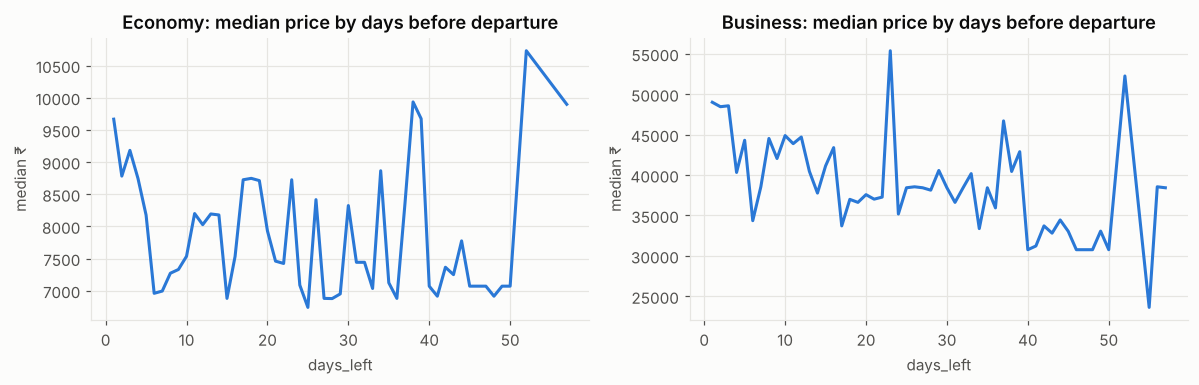

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, cls in zip(ax, ['Economy', 'Business']):
    s = train[train.flight_class == cls].groupby('days_left').price.median()
    a.plot(s.index, s.values, color=BLUE, linewidth=2)
    a.set(title=f'{cls}: median price by days before departure', xlabel='days_left', ylabel='median ₹')
plt.tight_layout(); plt.show()

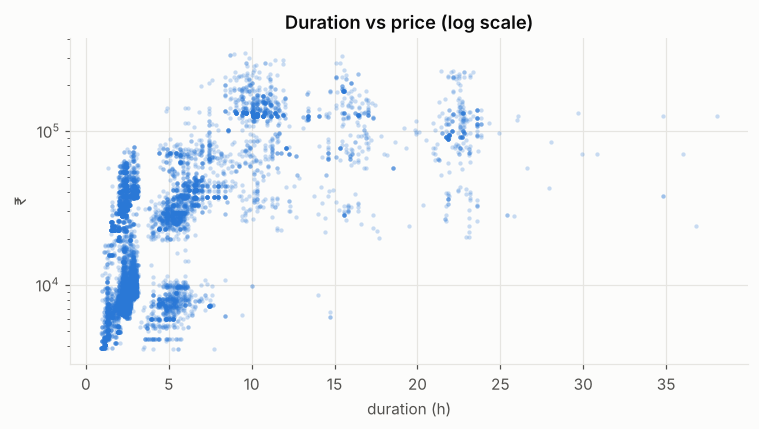

corr(duration, price) = 0.699 | corr(days_left, price) = -0.023


In [11]:
d = train.dropna(subset=['duration'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(d.duration, d.price, s=8, alpha=0.25, color=BLUE, linewidths=0)
ax.set(yscale='log', title='Duration vs price (log scale)', xlabel='duration (h)', ylabel='₹')
plt.tight_layout(); plt.show()
print('corr(duration, price) =', round(d[['duration','price']].corr().iloc[0,1], 3),
      '| corr(days_left, price) =', round(train[['days_left','price']].corr().iloc[0,1], 3))

- Class dominates price: Business is roughly 8× Economy.
- Prices jump in the last ~2 weeks before departure, which the near-zero linear correlation for `days_left` hides.
- Duration is strongly related to price. It's also 20% missing, which makes its imputation important.

### 2.4 Duplicate rows

In [12]:
inputs = [c for c in train.columns if c not in ('id', 'price')]
grp = train.groupby(inputs, dropna=False)['price']
dup = grp.transform('size') > 1
same_price = (grp.transform('max') == grp.transform('min'))[dup].mean()
twin_test = test.merge(train[inputs].drop_duplicates(), on=inputs, how='left', indicator=True)['_merge'].eq('both').mean()
print(f"train rows identical to another train row in every input column: {dup.mean():.1%}")
print(f"  ... of which the duplicates have exactly the same price: {same_price:.1%}")
print(f"test rows identical to a train row in every input column: {twin_test:.1%}")

train rows identical to another train row in every input column: 4.0%
  ... of which the duplicates have exactly the same price: 88.6%
test rows identical to a train row in every input column: 3.9%


Some rows are exact repeats. They're kept for training, because they're real observations. Section 9 uses them directly: a test row identical to a train row takes that row's price. The counts here use the raw columns, missing values included; section 9 matches on the cleaned columns.

## 3. Missing values
### 3.1 `airline`: recovered exactly from the flight code
The `flight` column (e.g. `IX 1070`) starts with a carrier code. Every code maps to exactly one airline on the rows where both are known, so missing airlines can be filled with certainty rather than guessed.

In [13]:
for d in (train, test):
    d['flight_code'] = d['flight'].str.extract(r'^([A-Za-z0-9]+)\s')[0]
both = pd.concat([train, test])
n_airlines_per_code = both.dropna(subset=['airline']).groupby('flight_code').airline.nunique()
print('airlines per flight code:', n_airlines_per_code.value_counts().to_dict(), '-> 1:1 mapping')

code_to_airline = (train.dropna(subset=['airline']).groupby('flight_code')['airline']
                        .agg(lambda x: x.value_counts().index[0]))
for name, d in [('train', train), ('test', test)]:
    before = d.airline.isna().sum()
    d['airline'] = d['airline'].fillna(d['flight_code'].map(code_to_airline))
    d['airline'] = d['airline'].fillna(train['airline'].mode()[0])   # safety net for unseen codes
    print(f'{name}: airline nulls {before} -> {d.airline.isna().sum()}')

airlines per flight code: {1: 20} -> 1:1 mapping
train: airline nulls 3089 -> 0
test: airline nulls 799 -> 0


### 3.2 `duration`: compare 8 imputation methods, pick the best
To get a fair comparison, hide 20% of the *known* durations, fill them with each method, and measure the error against the true values.

In [14]:
CAT_COLS = ['airline','source_city','departure_time','stops','arrival_time','destination_city','flight_class']
df = train.dropna(subset=['duration']).copy()
df['route'] = df.source_city + '_' + df.destination_city
mask_idx = df.sample(frac=0.2, random_state=42).index
truth = df.loc[mask_idx, 'duration']
dm = df.copy(); dm.loc[mask_idx, 'duration'] = np.nan
res = {}
res['global mean'] = (truth - dm.duration.mean()).abs().mean()
res['global median'] = (truth - dm.duration.median()).abs().mean()
def group_median(keys):
    g = dm.groupby(keys).duration.median()
    p = pd.Series(pd.MultiIndex.from_frame(dm.loc[mask_idx, keys]).map(g), index=mask_idx).astype(float)
    return p.fillna(dm.duration.median())
for keys in [['stops'], ['route'], ['route','stops'], ['route','stops','flight_class']]:
    res['group median: ' + '+'.join(keys)] = (truth - group_median(keys)).abs().mean()
oe_tmp = OrdinalEncoder(); enc = dm.copy(); enc[CAT_COLS] = oe_tmp.fit_transform(enc[CAT_COLS].astype(str))
feat = CAT_COLS + ['days_left']
knn_out = KNNImputer(n_neighbors=7).fit_transform(enc[feat + ['duration']])
res['KNN imputer (k=7)'] = (truth - pd.Series(knn_out[:, -1], index=enc.index).loc[mask_idx]).abs().mean()
fit_part = enc.loc[~enc.index.isin(mask_idx)]
rf_imp = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1).fit(fit_part[feat], fit_part.duration)
res['Random Forest regression'] = (truth - rf_imp.predict(enc.loc[mask_idx, feat])).abs().mean()
# Flight-number lookup: same flight + route + stops + times -> same duration.
# The pool is the non-hidden train durations plus test's known durations (duration is an input, not the target).
te_known = test.dropna(subset=['duration']).assign(route=lambda d: d.source_city + '_' + d.destination_city)
pool = pd.concat([dm[dm.duration.notna()], te_known])
lk = pd.Series(np.nan, index=mask_idx)
for keys in [['flight','route','stops','departure_time','arrival_time'], ['flight','route','stops'], ['flight','route']]:
    g = pool.groupby(keys).duration.median(); miss = lk.isna()
    lk[miss] = pd.MultiIndex.from_frame(dm.loc[lk.index[miss], keys]).map(g).values
covered = lk.notna()
print(f"flight lookup covers {covered.mean():.1%} of hidden durations; MAE on those = {(truth[covered] - lk[covered]).abs().mean():.3f} h")
lk = lk.fillna(pd.Series(rf_imp.predict(enc.loc[mask_idx, feat]), index=mask_idx))
res['Flight-number lookup (+RF fallback)'] = (truth - lk).abs().mean()
imp = pd.Series(res).sort_values()
print(imp.round(3).to_string())

flight lookup covers 97.4% of hidden durations; MAE on those = 0.098 h
Flight-number lookup (+RF fallback)       0.132
Random Forest regression                  0.293
group median: route+stops+flight_class    0.825
group median: route+stops                 0.898
KNN imputer (k=7)                         0.983
group median: stops                       2.067
global median                             2.067
group median: route                       2.067
global mean                               2.696


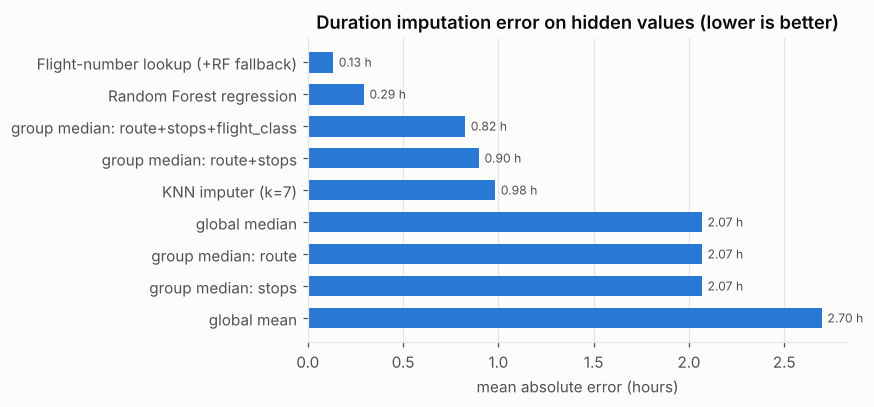

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
s = imp.sort_values(ascending=False)
ax.barh(s.index, s.values, color=BLUE, height=0.65)
for i, v in enumerate(s.values): ax.text(v + 0.03, i, f'{v:.2f} h', va='center', color=INK2, fontsize=8)
ax.set(title='Duration imputation error on hidden values (lower is better)', xlabel='mean absolute error (hours)')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

The flight-number lookup is by far the most accurate method. On the rows it covers, the error is about a minute. Random Forest regression, which is ~5× better than the median, fills the rest. RF is fitted on train rows whose duration was originally known.

In [16]:
ORIG_KNOWN = train['duration'].notna().values
# Step 1: flight-number lookup, from the most specific key to the least specific
for d in (train, test): d['_route'] = d['source_city'] + '_' + d['destination_city']
pool = pd.concat([train, test])[lambda d: d['duration'].notna()]
for keys in [['flight','_route','stops','departure_time','arrival_time'], ['flight','_route','stops'], ['flight','_route']]:
    lkp = pool.groupby(keys)['duration'].median().rename('_fill')
    for d in (train, test):
        m = d['duration'].isna()
        if m.any():
            d.loc[m, 'duration'] = d.loc[m, keys].merge(lkp, left_on=keys, right_index=True, how='left')['_fill'].values
    print(f"after lookup on {'+'.join(k.strip('_') for k in keys):45s} missing: train={train.duration.isna().sum():4d}  test={test.duration.isna().sum():3d}")
for d in (train, test): d.drop(columns='_route', inplace=True)

# Step 2: Random Forest regression for whatever the lookup couldn't fill
oe_imp = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(train[CAT_COLS].astype(str))
enc_imp = lambda d: np.hstack([oe_imp.transform(d[CAT_COLS].astype(str)), d[['days_left']].values])
rf_imputer = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=RNG, n_jobs=-1)
rf_imputer.fit(enc_imp(train.loc[ORIG_KNOWN]), train.loc[ORIG_KNOWN, 'duration'])
known = train['duration'].notna()
if (~known).any(): train.loc[~known, 'duration'] = rf_imputer.predict(enc_imp(train.loc[~known]))
tm = test['duration'].isna()
test.loc[tm, 'duration'] = rf_imputer.predict(enc_imp(test.loc[tm]))
print('remaining nulls  train:', int(train.isna().sum().sum()), '| test:', int(test.isna().sum().sum()))

after lookup on flight+route+stops+departure_time+arrival_time missing: train=  96  test= 20
after lookup on flight+route+stops                            missing: train=  72  test= 15
after lookup on flight+route                                  missing: train=  72  test= 15


remaining nulls  train: 0 | test: 0


## 4. Feature engineering and encoding

In [17]:
def engineer(df):
    df = df.copy()
    df['route'] = df['source_city'] + '_' + df['destination_city']
    df['is_direct'] = (df['stops'] == 'zero').astype(int)
    df['days_left_bucket'] = pd.cut(df['days_left'], bins=[0,3,7,15,30,60],
                                    labels=['last_min','week','two_week','month','far']).astype(str)
    df['duration_bucket'] = pd.cut(df['duration'], bins=[0,2,5,10,40],
                                   labels=['short','medium','long','very_long']).astype(str)
    df['stops_num'] = df['stops'].map({'zero':0, 'one':1, 'two_or_more':2})
    return df
train, test = engineer(train), engineer(test)
ALL_CAT = CAT_COLS + ['route','days_left_bucket','duration_bucket']
ALL_NUM = ['days_left','duration','is_direct','stops_num']
y = train['price'].values.astype(float)
yl = np.log1p(y)
print('categorical:', ALL_CAT); print('numeric:', ALL_NUM)

categorical: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'route', 'days_left_bucket', 'duration_bucket']
numeric: ['days_left', 'duration', 'is_direct', 'stops_num']


`flight` and `flight_code` are dropped after recovering `airline`. The code is redundant with airline, and the full flight number (1,070 levels, ~10 rows each) overfits.

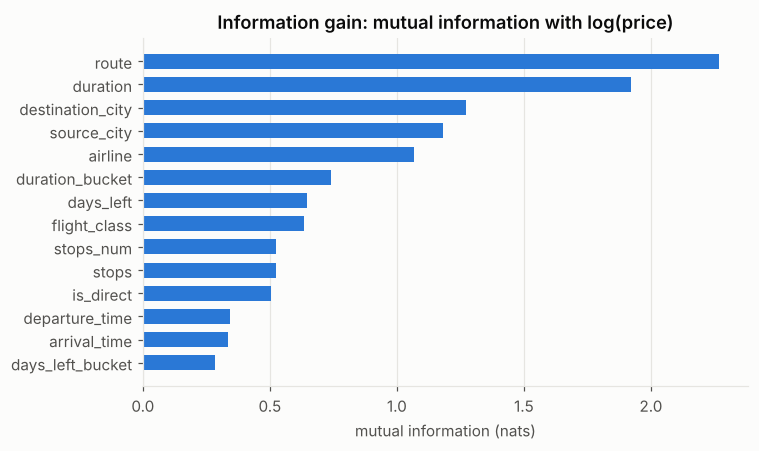

In [18]:
mi_df = train[ALL_CAT].astype(str).apply(lambda s: s.astype('category').cat.codes)
mi = mutual_info_regression(np.hstack([mi_df.values, train[ALL_NUM].values]), yl,
                            discrete_features=[True]*len(ALL_CAT) + [False]*len(ALL_NUM), random_state=RNG)
mi = pd.Series(mi, index=ALL_CAT + ALL_NUM).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(mi.index, mi.values, color=BLUE, height=0.65)
ax.set(title='Information gain: mutual information with log(price)', xlabel='mutual information (nats)')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

In [19]:
# Tree models: ordinal codes (and pandas 'category' for native categorical XGBoost/LightGBM)
oe_final = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(train[ALL_CAT].astype(str))
def tree_features(df):
    X = pd.DataFrame(oe_final.transform(df[ALL_CAT].astype(str)), columns=ALL_CAT, index=df.index).astype(int)
    for c in ALL_NUM: X[c] = df[c].values
    return X
Xtr, Xte = tree_features(train), tree_features(test)
Xtr_c, Xte_c = Xtr.copy(), Xte.copy()
for c in ALL_CAT:
    cats = sorted(Xtr[c].unique())
    Xtr_c[c] = pd.Categorical(Xtr[c], categories=cats); Xte_c[c] = pd.Categorical(Xte[c], categories=cats)
cat_idx = list(range(len(ALL_CAT)))

# Linear-family models: one-hot (levels with <20 rows grouped as 'infrequent') + scaling
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, min_frequency=20).fit(train[ALL_CAT].astype(str))
lin = lambda d: np.hstack([d[ALL_NUM].values, ohe.transform(d[ALL_CAT].astype(str))])
scaler = StandardScaler().fit(lin(train))
Xtr_lin, Xte_lin = scaler.transform(lin(train)), scaler.transform(lin(test))
print('tree features', Xtr.shape, '| linear features', Xtr_lin.shape)

tree features (15589, 14) | linear features (15589, 85)


### 4.1 Encoding comparison, including rare-airline grouping
LightGBM, 5-fold CV, log target. Lower MAE is better.

In [20]:
if RUN_COMPARISONS:
    FOLDS = list(KFold(5, shuffle=True, random_state=RNG).split(Xtr))
    def lgb_cv(X, cat=None):
        maes = []
        for tr, va in FOLDS:
            m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=RNG, verbosity=-1)
            m.fit(X.iloc[tr], yl[tr], **({'categorical_feature': cat} if cat else {}))
            maes.append(mean_absolute_error(y[va], np.expm1(m.predict(X.iloc[va]))))
        return np.mean(maes)
    base = train[CAT_COLS].astype(str)
    nums = train[['days_left','duration']].reset_index(drop=True)
    enc_res = {}
    enc_res['ordinal'] = lgb_cv(pd.concat([pd.DataFrame(OrdinalEncoder().fit_transform(base), columns=CAT_COLS), nums], axis=1))
    g = base.copy(); rare = g.airline.value_counts()[lambda s: s < 30].index; g.loc[g.airline.isin(rare), 'airline'] = 'Other'
    enc_res['ordinal + rare airlines grouped (<30 rows)'] = lgb_cv(pd.concat([pd.DataFrame(OrdinalEncoder().fit_transform(g), columns=CAT_COLS), nums], axis=1))
    enc_res['frequency encoding'] = lgb_cv(pd.concat([base.apply(lambda s: s.map(s.value_counts(normalize=True))).reset_index(drop=True), nums], axis=1))
    # out-of-fold target encoding (computed inside each fold to avoid leakage), smoothing = 10
    te = pd.DataFrame(index=range(len(base)), columns=CAT_COLS, dtype=float)
    for a, b in KFold(5, shuffle=True, random_state=1).split(base):
        for c in CAT_COLS:
            st = pd.DataFrame({'k': base[c].values[a], 'y': yl[a]}).groupby('k').y.agg(['mean','count'])
            sm = (st['mean']*st['count'] + yl[a].mean()*10) / (st['count'] + 10)
            te.loc[b, c] = base[c].iloc[b].map(sm).fillna(yl[a].mean()).values
    enc_res['target encoding (out-of-fold, smoothed)'] = lgb_cv(pd.concat([te, nums], axis=1))
    nat = base.apply(lambda s: s.astype('category')).reset_index(drop=True)
    enc_res['LightGBM native categorical'] = lgb_cv(pd.concat([nat, nums], axis=1), cat=CAT_COLS)
    display(pd.Series(enc_res).sort_values().round(1).rename('CV MAE (₹)').to_frame())

,CV MAE (₹)
LightGBM native categorical,3730.3
frequency encoding,3731.6
ordinal + rare airlines grouped (<30 rows),3755.6
ordinal,3773.2
"target encoding (out-of-fold, smoothed)",3919.8


- Native categorical and frequency encoding come out best. Grouping rare airlines does *not* help: tree splits already isolate rare levels.
- Tree models therefore use ordinal or native categories.
- Linear models get one-hot encoding, where `min_frequency=20` folds the rarest levels together.

## 5. Target transform: raw vs log

In [21]:
if RUN_COMPARISONS:
    for name, target, inv in [('raw price', y, lambda p: p), ('log1p(price)', yl, np.expm1)]:
        r2s, maes = [], []
        for tr, va in FOLDS:
            m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=RNG, verbosity=-1)
            m.fit(Xtr.iloc[tr], target[tr], categorical_feature=cat_idx); p = inv(m.predict(Xtr.iloc[va]))
            r2s.append(r2_score(y[va], p)); maes.append(mean_absolute_error(y[va], p))
        print(f'LightGBM on {name:13s} R2={np.mean(r2s):.4f}  MAE=₹{np.mean(maes):,.0f}')

LightGBM on raw price     R2=0.9259  MAE=₹3,801


LightGBM on log1p(price)  R2=0.9277  MAE=₹3,515


The log target gives a similar R² and a clearly lower MAE, so every model below trains on `log1p(price)`.

## 5b. Feature selection
Three complementary views of which inputs to keep:
1. **Filter:** information gain (mutual information, section 4) and correlation between the numeric features (redundancy).
2. **Wrapper / ablation:** retrain XGBoost (native categorical) in 5-fold CV with feature groups removed, or the flight number added.
3. **Model-based:** permutation importance, i.e. how much held-out accuracy drops when one feature is shuffled.

Every score is out-of-fold and reported on three scales: R² on √price, log price and price.

In [22]:
print('Correlation between numeric features:')
display(train[ALL_NUM].corr().round(3))
print('Mutual information with log(price), highest first:')
display(mi.sort_values(ascending=False).round(3).rename('MI').to_frame().T)

Correlation between numeric features:


,days_left,duration,is_direct,stops_num
days_left,1.000,-0.021,-0.002,0.001
duration,-0.021,1.000,-0.718,0.727
is_direct,-0.002,-0.718,1.000,-0.990
stops_num,0.001,0.727,-0.990,1.000


Mutual information with log(price), highest first:


,route,duration,destination_city,source_city,airline,duration_bucket,days_left,flight_class,stops_num,stops,is_direct,departure_time,arrival_time,days_left_bucket
MI,2.269,1.92,1.271,1.181,1.066,0.741,0.646,0.635,0.526,0.525,0.505,0.342,0.335,0.284


In [23]:
if RUN_COMPARISONS:
    xp_fs = dict(n_estimators=700, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                 random_state=RNG, tree_method='hist', verbosity=0)
    def fs_three(pl):
        p = np.expm1(pl); f = lambda a, b: 1 - np.sum((b - a)**2) / np.sum((a - a.mean())**2)
        return f(np.sqrt(y), np.sqrt(p)), f(yl, pl), f(y, p)
    def fs_cv(cols, add_flight=False):
        X = Xtr_c[cols].copy()
        if add_flight: X['flight'] = pd.Categorical(train['flight'])
        o = np.zeros(len(y))
        for a, b in FOLDS: o[b] = xgb.XGBRegressor(**xp_fs, enable_categorical=True).fit(X.iloc[a], yl[a]).predict(X.iloc[b])
        return o
    ALL14 = list(Xtr_c.columns)
    RAW9 = ['airline','source_city','departure_time','stops','arrival_time','destination_city','flight_class','days_left','duration']
    drop = lambda *cs: [c for c in ALL14 if c not in cs]
    SETS = {'all 14 features': ALL14, 'raw columns only (9)': RAW9,
            'minus route': drop('route'), 'minus days_left_bucket': drop('days_left_bucket'),
            'minus duration_bucket': drop('duration_bucket'), 'minus is_direct + stops_num': drop('is_direct', 'stops_num'),
            'minus duration (+ its bucket)': drop('duration', 'duration_bucket'), 'minus days_left (+ its bucket)': drop('days_left', 'days_left_bucket'),
            'minus departure/arrival time': drop('departure_time', 'arrival_time'), 'minus airline': drop('airline')}
    rows = {}
    for name, cols in SETS.items(): rows[name] = (len(cols),) + fs_three(fs_cv(cols))
    rows['plus flight number (1,070 levels)'] = (15,) + fs_three(fs_cv(ALL14, add_flight=True))
    abl = pd.DataFrame(rows, index=['n features', 'R2 sqrt(price)', 'R2 log(price)', 'R2 price']).T
    for c in abl.columns[1:]: abl['Δ ' + c.split()[1]] = abl[c] - abl.loc['all 14 features', c]
    display(abl.style.format({'n features': '{:.0f}', **{c: '{:.5f}' for c in abl.columns[1:4]}, **{c: '{:+.5f}' for c in abl.columns[4:]}}))

,n features,R2 sqrt(price),R2 log(price),R2 price,Δ sqrt(price),Δ log(price),Δ price
all 14 features,14,0.96935,0.98347,0.93081,+0.00000,+0.00000,+0.00000
raw columns only (9),9,0.97057,0.98298,0.93534,+0.00123,-0.00050,+0.00453
minus route,13,0.97036,0.98312,0.93458,+0.00101,-0.00035,+0.00377
minus days_left_bucket,13,0.96958,0.98347,0.93183,+0.00023,+0.00000,+0.00102
minus duration_bucket,13,0.96934,0.98356,0.93048,-0.00000,+0.00009,-0.00033
minus is_direct + stops_num,12,0.96922,0.98336,0.93061,-0.00012,-0.00011,-0.00020
minus duration (+ its bucket),12,0.96885,0.98335,0.92984,-0.00050,-0.00013,-0.00097
minus days_left (+ its bucket),12,0.96016,0.96827,0.92167,-0.00919,-0.01520,-0.00914
minus departure/arrival time,12,0.96481,0.97717,0.92642,-0.00453,-0.00630,-0.00439
minus airline,13,0.95572,0.97605,0.90460,-0.01363,-0.00742,-0.02622


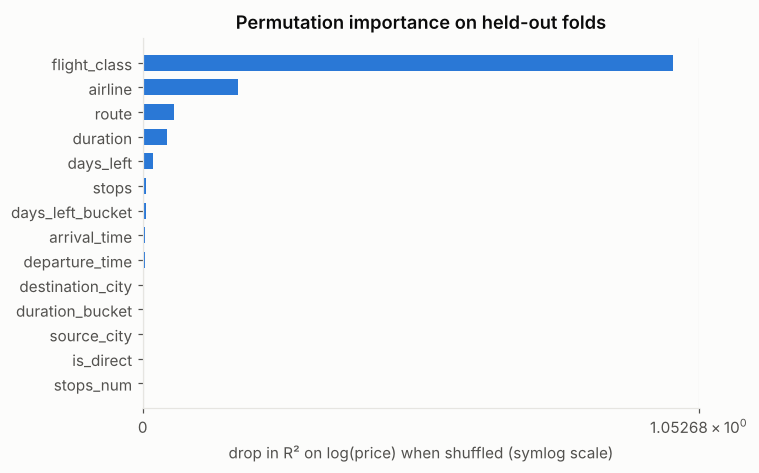

flight_class        1.0025
airline             0.1803
route               0.0580
duration            0.0451
days_left           0.0188
stops               0.0054
days_left_bucket    0.0051
arrival_time        0.0044
departure_time      0.0041
destination_city    0.0021
duration_bucket     0.0021
source_city         0.0013
is_direct           0.0001
stops_num           0.0000


In [24]:
if RUN_COMPARISONS:
    rng_pi = np.random.default_rng(0); drops = {c: [] for c in ALL14}
    for a, b in FOLDS:
        m = xgb.XGBRegressor(**xp_fs, enable_categorical=True).fit(Xtr_c.iloc[a], yl[a]); Xv = Xtr_c.iloc[b]
        base_r2 = r2_score(yl[b], m.predict(Xv))
        for c in ALL14:
            for _ in range(3):
                Xp = Xv.copy(); Xp[c] = Xp[c].values[rng_pi.permutation(len(Xp))]
                drops[c].append(base_r2 - r2_score(yl[b], m.predict(Xp)))
    pi = pd.Series({c: np.mean(v) for c, v in drops.items()}).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4.4))
    ax.barh(pi.index, pi.values, color=BLUE, height=0.65)
    ax.set(xscale='symlog', title='Permutation importance on held-out folds', xlabel='drop in R² on log(price) when shuffled (symlog scale)')
    ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()
    print(pi.sort_values(ascending=False).round(4).to_string())

In [25]:
if RUN_COMPARISONS:
    # does the selection result carry over to the whole 3-model blend?
    def fs_cv_model(make, X):
        o = np.zeros(len(y))
        for a, b in FOLDS: o[b] = make().fit(X[a], yl[a]).predict(X[b])
        return o
    def blend_oof_for(cols):
        o = {'xgb_cat': fs_cv(cols)}
        o['rf'] = fs_cv_model(lambda: RandomForestRegressor(n_estimators=600, max_depth=18, min_samples_leaf=2, random_state=RNG, n_jobs=-1), Xtr[cols].values)
        o['et'] = fs_cv_model(lambda: ExtraTreesRegressor(n_estimators=500, max_depth=20, min_samples_leaf=2, random_state=RNG, n_jobs=-1), Xtr[cols].values)
        return 0.55 * o['xgb_cat'] + 0.30 * o['rf'] + 0.15 * o['et']
    fs_blend = {'blend on all 14 features': blend_oof_for(ALL14), 'blend on raw 9 features': blend_oof_for(RAW9)}
    display(pd.DataFrame({k: fs_three(v) for k, v in fs_blend.items()}, index=['R2 sqrt(price)', 'R2 log(price)', 'R2 price']).T.style.format('{:.5f}'))

,R2 sqrt(price),R2 log(price),R2 price
blend on all 14 features,0.97020,0.98361,0.93274
blend on raw 9 features,0.97091,0.98329,0.93567


**What feature selection shows**
- **Essential:** `flight_class`, `airline`, `days_left`, `duration` and the departure/arrival slots. Removing any of them costs up to 0.015 log-R², and they top the permutation importance.
- **Redundant:** `is_direct` and `stops_num` are 99% correlated with each other and re-encode `stops`. Their permutation importance is ≈0, and removing them changes nothing.
- **Harmful:** the raw flight number (1,070 levels, ~10 rows each) overfits. Adding it costs ~0.005 log-R², so it's excluded.
- **Engineered features are a trade-off:** the 9 raw columns alone score *higher* on R² for √price and price, but *lower* on log price. The same holds for the full blend. The engineered `route`, booking-window and duration buckets help the cheap end of the price range (log scale) and cost a little at the expensive end.

**Decision:** the submitted model **H** uses all 14 features (`FEATURE_SET = 'all14'`, public LB 0.96317). `FEATURE_SET = 'raw9'` produces candidate **J**, the same blend on the 9 raw columns. The leaderboard result decides between them.

## 6. Model comparison: 5-fold cross-validation
The same folds are used for every model. The out-of-fold (OOF) predictions are kept for the blend in section 7.

In [26]:
if RUN_COMPARISONS:
    def cv_model(make, X, fit_kw=None, poly=None):
        oof = np.zeros(len(y))
        for tr, va in FOLDS:
            Xa = X.iloc[tr] if hasattr(X, 'iloc') else X[tr]; Xb = X.iloc[va] if hasattr(X, 'iloc') else X[va]
            if poly is not None:
                pf = PolynomialFeatures(degree=poly, include_bias=False); Xa = pf.fit_transform(Xa); Xb = pf.transform(Xb)
            m = make(); m.fit(Xa, yl[tr], **(fit_kw or {})); oof[va] = m.predict(Xb)
        return oof

    xp = dict(n_estimators=700, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8,
              random_state=RNG, tree_method='hist', verbosity=0)
    Xtr_poly = np.hstack([Xtr_lin[:, :len(ALL_NUM)],
                          TruncatedSVD(n_components=20, random_state=RNG).fit_transform(Xtr_lin[:, len(ALL_NUM):])])
    dur_only = Xtr_lin[:, [ALL_NUM.index('duration')]]
    MODELS = {
     'Simple linear regression (duration only)': (lambda: LinearRegression(), dur_only, None, None),
     'Multiple linear regression (all features)': (lambda: LinearRegression(), Xtr_lin, None, None),
     'Polynomial regression (degree 2)': (lambda: LinearRegression(), Xtr_poly, None, 2),
     'Ridge (alpha=5)': (lambda: Ridge(alpha=5.0), Xtr_lin, None, None),
     'Lasso (alpha=0.001)': (lambda: Lasso(alpha=0.001, max_iter=5000), Xtr_lin, None, None),
     'KNN (k=15)': (lambda: KNeighborsRegressor(n_neighbors=15, weights='distance'), Xtr_lin, None, None),
     'Decision tree': (lambda: DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=RNG), Xtr.values, None, None),
     'rf': (lambda: RandomForestRegressor(n_estimators=600, max_depth=18, min_samples_leaf=2, random_state=RNG, n_jobs=-1), Xtr.values, None, None),
     'et': (lambda: ExtraTreesRegressor(n_estimators=500, max_depth=20, min_samples_leaf=2, random_state=RNG, n_jobs=-1), Xtr.values, None, None),
     'gb': (lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, random_state=RNG), Xtr.values, None, None),
     'lgb': (lambda: lgb.LGBMRegressor(n_estimators=800, learning_rate=0.025, num_leaves=48, subsample=0.8,
                                       colsample_bytree=0.8, random_state=RNG, verbosity=-1), Xtr.values, {'categorical_feature': cat_idx}, None),
     'xgb': (lambda: xgb.XGBRegressor(**xp), Xtr.values, None, None),
     'xgb_cat': (lambda: xgb.XGBRegressor(**xp, enable_categorical=True), Xtr_c, None, None),
    }
    if RUN_CATBOOST:
        from catboost import CatBoostRegressor
        Xtr_str = Xtr.copy(); Xtr_str[ALL_CAT] = Xtr_str[ALL_CAT].astype(str)
        MODELS['CatBoost'] = (lambda: CatBoostRegressor(iterations=700, learning_rate=0.04, depth=8, random_seed=RNG,
                                                        verbose=False, cat_features=cat_idx), Xtr_str, None, None)
    NICE = {'rf': 'Random forest', 'et': 'Extra trees', 'gb': 'Gradient boosting', 'lgb': 'LightGBM',
            'xgb': 'XGBoost (ordinal)', 'xgb_cat': 'XGBoost (native categorical)'}
    OOF, rows = {}, []
    for name, (make, X, kw, poly) in MODELS.items():
        t = time.time(); o = cv_model(make, X, kw, poly); OOF[name] = o; p = np.expm1(o)
        rows.append({'model': NICE.get(name, name), 'R2': r2_score(y, p), 'MAE': mean_absolute_error(y, p),
                     'RMSE': np.sqrt(mean_squared_error(y, p)), 'seconds': round(time.time() - t)})
        print(f"{NICE.get(name, name):42s} R2={rows[-1]['R2']:.4f}  MAE=₹{rows[-1]['MAE']:,.0f}  ({rows[-1]['seconds']}s)")
    results = pd.DataFrame(rows).sort_values('R2', ascending=False).reset_index(drop=True)
    display(results.style.format({'R2': '{:.4f}', 'MAE': '₹{:,.0f}', 'RMSE': '₹{:,.0f}'}))

Simple linear regression (duration only)   R2=-1.6156  MAE=₹21,697  (0s)


Multiple linear regression (all features)  R2=0.8576  MAE=₹5,819  (0s)


Polynomial regression (degree 2)           R2=0.8693  MAE=₹5,557  (2s)
Ridge (alpha=5)                            R2=0.8576  MAE=₹5,818  (0s)


Lasso (alpha=0.001)                        R2=0.8578  MAE=₹5,794  (1s)


KNN (k=15)                                 R2=0.8437  MAE=₹5,168  (1s)
Decision tree                              R2=0.9100  MAE=₹4,059  (0s)


...

LightGBM                                   R2=0.9293  MAE=₹3,456  (11s)


XGBoost (ordinal)                          R2=0.9313  MAE=₹3,400  (7s)


XGBoost (native categorical)               R2=0.9308  MAE=₹3,235  (13s)


CatBoost                                   R2=0.9180  MAE=₹3,945  (107s)


,model,R2,MAE,RMSE,seconds
0,XGBoost (ordinal),0.9313,"₹3,400","₹10,258",7
1,XGBoost (native categorical),0.9308,"₹3,235","₹10,292",13
2,Random forest,0.9301,"₹3,317","₹10,342",49
3,LightGBM,0.9293,"₹3,456","₹10,402",11
4,Gradient boosting,0.9288,"₹3,794","₹10,437",24
5,Extra trees,0.9266,"₹3,308","₹10,600",35
6,CatBoost,0.9180,"₹3,945","₹11,206",107
7,Decision tree,0.9100,"₹4,059","₹11,738",0
8,Polynomial regression (degree 2),0.8693,"₹5,557","₹14,145",2
9,Lasso (alpha=0.001),0.8578,"₹5,794","₹14,756",1


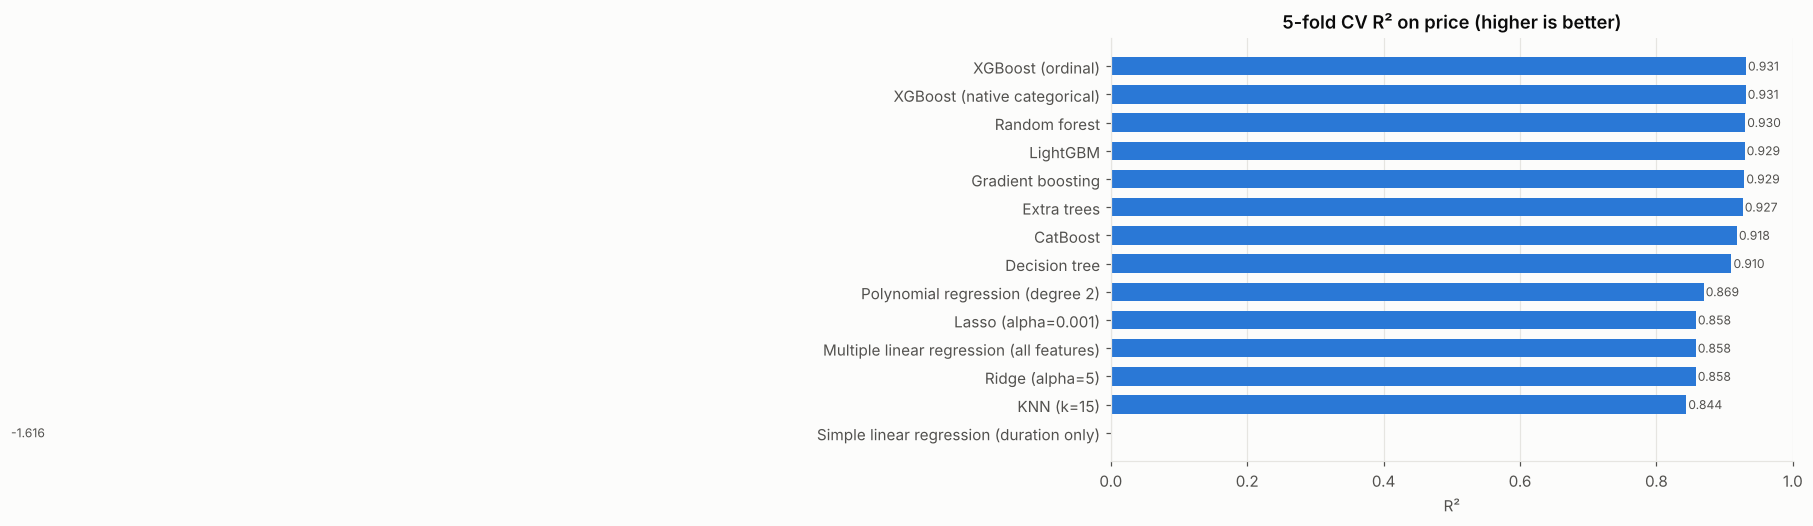

In [27]:
if RUN_COMPARISONS:
    r = results.sort_values('R2')
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(r.model, r.R2, color=BLUE, height=0.65)
    for i, v in enumerate(r.R2): ax.text(v + 0.003, i, f'{v:.3f}', va='center', color=INK2, fontsize=8)
    ax.set(title='5-fold CV R² on price (higher is better)', xlabel='R²', xlim=(max(0, r.R2.min() - 0.05), 1))
    ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

- Linear-family models plateau around R² ≈ 0.86. Price depends on interactions (route × class × booking window) that they can't represent; polynomial terms help a little.
- Tree ensembles capture those interactions and reach ≈ 0.93.
- *Simple* linear regression on duration alone scores a negative R² on price. One feature can't separate Economy from Business fares, and converting its log-scale predictions back to ₹ magnifies the misses on expensive tickets. This is why the multiple regression, which uses all features, does so much better (0.86).

## 7. Blend: search the weights on out-of-fold predictions
Every combination of the six strongest models is tried in 5% steps (53,130 combinations). The blend is averaged in log space and scored by MAE in ₹.

These weights were first chosen on the original features, where the lowest-MAE blend (0.96240) beat both the best-R² and equal-weight blends (0.96131). They are **kept fixed** here: 55% XGBoost (native categorical) / 30% RF / 15% Extra Trees. The search below re-runs on the improved durations for reference.

In [28]:
if RUN_COMPARISONS:
    names = ['xgb', 'xgb_cat', 'rf', 'lgb', 'et', 'gb']
    P = np.column_stack([OOF[n] for n in names]).astype(np.float32)
    def simplex(k, total):
        if k == 1: yield (total,); return
        for i in range(total + 1):
            for rest in simplex(k - 1, total - i): yield (i,) + rest
    W = (np.array(list(simplex(len(names), 20))) / 20).astype(np.float32)
    mae = np.empty(len(W)); r2 = np.empty(len(W)); ss = ((y - y.mean())**2).sum()
    for s in range(0, len(W), 1500):                      # chunked to keep memory low
        pr = np.expm1(P @ W[s:s+1500].T) - y[:, None]
        mae[s:s+1500] = np.abs(pr).mean(0); r2[s:s+1500] = 1 - (pr.astype(np.float64)**2).sum(0) / ss
    best = W[np.argmin(mae)]
    top = pd.DataFrame(W[np.argsort(mae)[:5]], columns=names); top['CV MAE'] = np.sort(mae)[:5]; top['CV R2'] = r2[np.argsort(mae)[:5]]
    print('lowest-MAE blend:', {n: float(w) for n, w in zip(names, best) if w > 0})
    display(top.style.format({**{n: '{:.2f}' for n in names}, 'CV MAE': '₹{:,.1f}', 'CV R2': '{:.5f}'}))

lowest-MAE blend: {'xgb_cat': 0.550000011920929, 'rf': 0.30000001192092896, 'et': 0.15000000596046448}


,xgb,xgb_cat,rf,lgb,et,gb,CV MAE,CV R2
0,0.00,0.55,0.30,0.00,0.15,0.00,"₹3,183.0",0.93274
1,0.00,0.55,0.25,0.00,0.20,0.00,"₹3,183.0",0.93257
2,0.00,0.60,0.25,0.00,0.15,0.00,"₹3,183.5",0.93264
3,0.00,0.60,0.30,0.00,0.10,0.00,"₹3,183.7",0.93278
4,0.00,0.55,0.20,0.00,0.25,0.00,"₹3,184.0",0.93238


In [29]:
WEIGHTS = {'xgb_cat': 0.55, 'rf': 0.30, 'et': 0.15}    # same weights as the 0.96240 / 0.96289 submissions (kept fixed)
if RUN_COMPARISONS:
    blend_oof = sum(OOF[k] * w for k, w in WEIGHTS.items()); p = np.expm1(blend_oof)
    eq = np.expm1((OOF['xgb'] + OOF['xgb_cat'] + OOF['rf']) / 3)
    print(f"final blend   CV R2={r2_score(y, p):.5f}  MAE=₹{mean_absolute_error(y, p):,.1f}  RMSE=₹{np.sqrt(mean_squared_error(y, p)):,.1f}")
    print(f"equal XGB/XGB-cat/RF  CV R2={r2_score(y, eq):.5f}  MAE=₹{mean_absolute_error(y, eq):,.1f}")

final blend   CV R2=0.93274  MAE=₹3,183.0  RMSE=₹10,147.6
equal XGB/XGB-cat/RF  CV R2=0.93321  MAE=₹3,229.4


## 8. Fit the 3-model blend on all of train and predict test
Uses the feature set chosen by `FEATURE_SET`. With `'all14'`, this blend alone is submission G (public LB 0.96289).

In [30]:
xp = dict(n_estimators=700, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8,
          random_state=RNG, tree_method='hist', verbosity=0)
RAW9 = ['airline','source_city','departure_time','stops','arrival_time','destination_city','flight_class','days_left','duration']
FEAT_COLS = list(Xtr.columns) if FEATURE_SET == 'all14' else RAW9
print('feature set:', FEATURE_SET, '->', len(FEAT_COLS), 'features')
t = time.time()
pred_log = {}
pred_log['xgb_cat'] = xgb.XGBRegressor(**xp, enable_categorical=True).fit(Xtr_c[FEAT_COLS], yl).predict(Xte_c[FEAT_COLS])
pred_log['rf'] = RandomForestRegressor(n_estimators=600, max_depth=18, min_samples_leaf=2, random_state=RNG,
                                       n_jobs=-1).fit(Xtr[FEAT_COLS].values, yl).predict(Xte[FEAT_COLS].values)
pred_log['et'] = ExtraTreesRegressor(n_estimators=500, max_depth=20, min_samples_leaf=2, random_state=RNG,
                                     n_jobs=-1).fit(Xtr[FEAT_COLS].values, yl).predict(Xte[FEAT_COLS].values)
blend_log = sum(pred_log[k] * w for k, w in WEIGHTS.items())     # the G prediction, log scale
final = np.clip(np.expm1(blend_log), 0, None)
submission = pd.DataFrame({'id': test['id'].values, 'price': final})
assert list(submission.columns) == list(sample.columns) and (submission.id.values == sample.id.values).all()
assert submission.price.notna().all() and (submission.price > 0).all()
submission.to_csv('submission_blend_only.csv', index=False)      # with 'all14' this is G (public LB 0.96289)
print(f'fitted in {time.time()-t:.0f}s -> submission_blend_only.csv', submission.shape)
submission.describe().T

feature set: all14 -> 14 features


fitted in 24s -> submission_blend_only.csv (3898, 2)


,count,mean,std,min,25%,50%,75%,max
id,3898.0,1949.500000,1125.400003,1.000000,975.250000,1949.500000,2923.750000,3898.000000
price,3898.0,29369.700182,37703.374146,3831.588532,7249.634643,9984.798477,35733.625766,267340.934089


## 9. Exact-twin override
8% of train rows share **every** feature with another train row: flight, route, stops, times, class, days_left and duration. Their prices never differ (std of log price 0.000), and ~8% of test rows have such a twin in train. For those rows, the twin's price beats any model.

Lookup order:
1. exact twin;
2. otherwise the same itinerary + class + days_left with a different duration (a handful of rows).

There are no fitted parameters.

The evidence cell below applies the same rule inside 5-fold CV. Each held-out row may only look up twins in the training folds.

In [31]:
K1 = ['flight', 'route', 'stops', 'departure_time', 'arrival_time', 'flight_class']
def twin_lookup(ref, ref_lp, query):
    """Mean log-price of identical rows in `ref`: exact twin first, then same itinerary+class+day."""
    out = np.full(len(query), np.nan)
    for key in [K1 + ['days_left', 'duration'], K1 + ['days_left']]:
        g = pd.DataFrame({**{c: ref[c].values for c in key}, 'lp': ref_lp}).groupby(key)['lp'].mean().rename('m')
        m = query[key].merge(g, left_on=key, right_index=True, how='left')['m'].values
        out = np.where(np.isnan(out), m, out)
    return out

def r2_three(pl, idx=None):
    idx = np.arange(len(y)) if idx is None else idx
    t, p = y[idx], np.expm1(pl[idx]); f = lambda a, b: 1 - np.sum((b - a)**2) / np.sum((a - a.mean())**2)
    return f(np.sqrt(t), np.sqrt(np.clip(p, 0, None))), f(yl[idx], pl[idx]), f(t, p)

if RUN_COMPARISONS:
    tw = np.full(len(y), np.nan)
    for a, b in FOLDS: tw[b] = twin_lookup(train.iloc[a], yl[a], train.iloc[b])
    h_oof = np.where(np.isnan(tw), blend_oof, tw); has = ~np.isnan(tw)
    print(f"held-out rows with a twin in the training folds: {has.mean():.1%}")
    print(f"on those rows, mean |log error|: blend {np.abs(blend_oof[has]-yl[has]).mean():.4f} -> twin {np.abs(tw[has]-yl[has]).mean():.4f}")
    display(pd.DataFrame([r2_three(blend_oof), r2_three(h_oof)], index=['blend (G)', 'blend + twins (H)'],
                         columns=['R2 sqrt(price)', 'R2 log(price)', 'R2 price']).style.format('{:.5f}'))

held-out rows with a twin in the training folds: 7.1%
on those rows, mean |log error|: blend 0.0513 -> twin 0.0108


,R2 sqrt(price),R2 log(price),R2 price
blend (G),0.97020,0.98361,0.93274
blend + twins (H),0.97071,0.98399,0.93344


In [32]:
over = twin_lookup(train, yl, test)
final_log = np.where(np.isnan(over), blend_log, over)
submission = pd.DataFrame({'id': test['id'].values, 'price': np.clip(np.expm1(final_log), 0, None)})
assert list(submission.columns) == list(sample.columns) and (submission.id.values == sample.id.values).all()
assert submission.price.notna().all() and (submission.price > 0).all()
submission.to_csv('submission.csv', index=False)
print(f"test rows set to their twin's train price: {(~np.isnan(over)).sum()} ({(~np.isnan(over)).mean():.1%})")
print('wrote submission.csv', submission.shape)
submission.describe().T

test rows set to their twin's train price: 325 (8.3%)
wrote submission.csv (3898, 2)


,count,mean,std,min,25%,50%,75%,max
id,3898.0,1949.500000,1125.400003,1.0,975.250000,1949.5,2923.750000,3898.000000
price,3898.0,29373.798358,37723.944206,3801.0,7261.706122,9943.0,35608.854579,267340.934089


## 10. Does it generalise? Checks on held-out predictions
All four checks use out-of-fold predictions, i.e. rows the models never trained on. The hidden 40% of the test set is never seen; these checks estimate how the pipeline behaves on unseen rows from the same distribution.

These checks use the 14-feature models (submission H).

In [33]:
if RUN_COMPARISONS:
    singles = {'XGBoost (native cat)': OOF['xgb_cat'], 'Random forest': OOF['rf'], 'Extra trees': OOF['et']}
    S = {**singles, 'G: 3-model blend': blend_oof, 'H: blend + twins': h_oof}
    # 1) per-fold stability
    fold_tab = pd.DataFrame({k: [r2_three(v, b)[0] for _, b in FOLDS] for k, v in S.items()},
                            index=[f'fold {i+1}' for i in range(5)])
    fold_tab.loc['mean'] = fold_tab.mean(); fold_tab.loc['std'] = fold_tab.iloc[:5].std()
    print('1) R2 on sqrt(price) for each held-out fold')
    display(fold_tab.style.format('{:.5f}'))
    wins = sum(fold_tab.iloc[f]['G: 3-model blend'] > fold_tab.iloc[f][list(singles)].max() for f in range(5))
    print(f"   blend beats every single model in {wins}/5 folds; twins improve the blend in "
          f"{int((fold_tab.iloc[:5]['H: blend + twins'] > fold_tab.iloc[:5]['G: 3-model blend']).sum())}/5 folds")
    # 2) weight sensitivity
    rng = np.random.default_rng(0); base_w = np.array([.55, .30, .15]); vals = []
    for _ in range(500):
        w = np.clip(base_w + rng.uniform(-.10, .10, 3), 0, None); w /= w.sum()
        vals.append(r2_three(w[0]*OOF['xgb_cat'] + w[1]*OOF['rf'] + w[2]*OOF['et'])[0])
    print(f"\n2) weights moved by up to ±10 points (500 draws): R2 sqrt {min(vals):.5f} – {max(vals):.5f} "
          f"(55/30/15 = {r2_three(blend_oof)[0]:.5f}) -> flat, not tuned to a knife-edge")
    # 3) simulated hidden 40%
    n40 = int(round(0.4 * len(test))); draws = [rng.choice(len(y), n40, replace=False) for _ in range(3000)]
    R = {k: np.array([r2_three(v, d)[0] for d in draws]) for k, v in S.items()}
    print(f"\n3) 3,000 random {n40}-row slices (the size of the hidden 40%)")
    display(pd.DataFrame({k: {'mean': v.mean(), '5th pct': np.quantile(v, .05), '95th pct': np.quantile(v, .95)} for k, v in R.items()}).T.style.format('{:.5f}'))
    print(f"   P(blend > best single model) = {np.mean(R['G: 3-model blend'] > R['XGBoost (native cat)']):.3f} | "
          f"P(H > G) = {np.mean(R['H: blend + twins'] > R['G: 3-model blend']):.3f}")

1) R2 on sqrt(price) for each held-out fold


,XGBoost (native cat),Random forest,Extra trees,G: 3-model blend,H: blend + twins
fold 1,0.96863,0.96808,0.96701,0.96971,0.97037
fold 2,0.96780,0.96434,0.96525,0.96814,0.96865
fold 3,0.96901,0.97031,0.96884,0.97085,0.97128
fold 4,0.97054,0.96917,0.96699,0.97130,0.97198
fold 5,0.97055,0.96752,0.96714,0.97072,0.97098
mean,0.96930,0.96788,0.96704,0.97014,0.97065
std,0.00121,0.00225,0.00127,0.00126,0.00126


   blend beats every single model in 5/5 folds; twins improve the blend in 5/5 folds



2) weights moved by up to ±10 points (500 draws): R2 sqrt 0.97007 – 0.97023 (55/30/15 = 0.97020) -> flat, not tuned to a knife-edge



3) 3,000 random 1559-row slices (the size of the hidden 40%)


,mean,5th pct,95th pct
XGBoost (native cat),0.96940,0.96188,0.97610
Random forest,0.96801,0.96134,0.97396
Extra trees,0.96714,0.96014,0.97366
G: 3-model blend,0.97025,0.96345,0.97639
H: blend + twins,0.97075,0.96393,0.97689


   P(blend > best single model) = 0.832 | P(H > G) = 0.987


In [34]:
# 4) adversarial validation: can a classifier tell train rows from test rows? (AUC 0.5 = no)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
adv_cols = ['airline','source_city','departure_time','stops','arrival_time','destination_city','flight_class','route','days_left','duration']
A = pd.concat([train[adv_cols], test[adv_cols]]).reset_index(drop=True)
for c in adv_cols:
    if not pd.api.types.is_numeric_dtype(A[c]): A[c] = A[c].astype('category')
lab = np.r_[np.zeros(len(train)), np.ones(len(test))]; prob = np.zeros(len(A))
for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(A, lab):
    prob[b] = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, verbosity=-1).fit(A.iloc[a], lab[a]).predict_proba(A.iloc[b])[:, 1]
print(f"4) adversarial validation AUC = {roc_auc_score(lab, prob):.3f}  (0.5 = test rows look exactly like train rows)")

4) adversarial validation AUC = 0.499  (0.5 = test rows look exactly like train rows)


## 11. Experiment and leaderboard log
Public leaderboard = ≈60% of the test set. The final standings use the hidden 40%.

| Submission | What changed | Public LB |
|---|---|---|
| RF 60% + LightGBM 40% | first blend | 0.95798 |
| XGB + XGB-cat + RF (equal) | added XGBoost | 0.96131 |
| D: absolute-loss XGB-cat (MAPE-tuned) | percentage-error objective | 0.95681 |
| E: absolute/squared hedge | same idea, hedged | 0.95913 |
| F: Optuna-tuned, 5-seed XGB-cat blend | hyper-parameter tuning | 0.96188 |
| C: XGB-cat 55 / RF 30 / ET 15 | lowest-MAE blend weights | 0.96240 |
| G: C + flight-number duration lookup | better imputation | 0.96289 |
| **H: G + exact-twin override** | duplicate rows | **0.96317** |
| J: H's blend on the 9 raw features (`FEATURE_SET='raw9'`) | feature selection | not yet submitted |

**Lessons**
- Percentage-error objectives under-predict on average and lost ~0.005.
- Tuning and blend-weight changes moved the score by less than leaderboard noise (≈±0.001).
- The real gains came from the data: exact airline recovery, flight-based duration recovery and exact duplicates.

**Tried and rejected in CV**
- Flight-number target encodings.
- Nearest-booking-day neighbour prices (model errors are uncorrelated across days).
- Looser "twin" keys, e.g. same airline instead of same flight (prices agree only ~54% of the time).